# Can machine learning split Pakistan into 5 social classes?

**Data:** HIES 2024-25, Section 6A (household consumption expenditure), with `weight.dta`.

**Question:** If we group households by how much they spend, what share of Pakistan's **households** falls in each of 5 classes (lower to upper)?

**Unit of analysis: the household.** Every share, median and model in this notebook is weighted by the **household weight** from `weight.dta`, so results read as "% of Pakistan's households". Without the weight, the results would describe only the 30,123 sampled households, not Pakistan.

### KNN or K-means?

| | K-means | KNN (k-nearest neighbours) |
|---|---|---|
| Type | **Unsupervised**: finds groups by itself | **Supervised**: needs groups that already exist |
| Input | Data only | Data **plus a label** for each row |
| Output | 5 groups (clusters) | Predicts the label of a new row |
| Use here | **Create** the 5 classes | **Check** whether the classes can be recognised from spending patterns |

KNN cannot divide society into classes on its own, because it has no labels to learn from. So this notebook:

1. builds each household's monthly spending per person from Section 6A;
2. makes the standard benchmark: **quintiles** (5 groups of exactly 20% of households each);
3. **Test A:** weighted K-means on spending per person, to see where the natural class boundaries fall;
4. **Test B:** weighted K-means on the *pattern* of spending (12 categories);
5. **KNN:** learns Test A's classes from the spending pattern;
6. shows what happens if you **forget the weight**.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, adjusted_rand_score

DATA = "../../HIES 2024_2025/Stata data/"
OUT = "outputs/"
os.makedirs(OUT, exist_ok=True)

CLASS_NAMES = {1: "Lower", 2: "Lower-middle", 3: "Middle", 4: "Upper-middle", 5: "Upper"}
CLASS_COLORS = ["#eda100", "#1baf7a", "#eb6834", "#2a78d6", "#e34948"]   # 5 clearly different colours (colour-blind checked)
INK, INK_2, GRID = "#0b0b0b", "#3d3c39", "#dcdbd6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # categorical slots 1-3 (blue, orange, aqua)
SURFACE = "#fcfcfb"
NAMES = [CLASS_NAMES[k] for k in range(1, 6)]
XPOS = np.arange(5)

def style(ax, ylabel):
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    # large text: the charts are shrunk to fit a web page (e.g. GitHub), so small fonts become unreadable
    "font.size": 14, "axes.titlesize": 17, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "axes.labelsize": 14, "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 13, "savefig.dpi": 150, "savefig.bbox": "tight", "savefig.pad_inches": 0.3,
})


def label_bars(ax, bars, fmt="{:.0f}"):
    """Write each bar's value just above it (call after set_ylim)."""
    gap = ax.get_ylim()[1] * 0.012
    for b in bars:
        top = b.get_y() + b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, top + gap, fmt.format(b.get_height() if b.get_y() == 0 else top),
                ha="center", va="bottom", fontsize=12, color=INK,
                bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1, alpha=0.85))


def text_colour_on(rgb):
    """Black or white text, whichever contrasts more with the background colour."""
    lin = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgb[:3]]
    return "white" if 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2] < 0.179 else INK
pd.set_option("display.float_format", "{:,.1f}".format)

def read(name, **kw):
    return pd.read_stata(DATA + name, convert_categoricals=False, **kw)

def wmean(x, w):
    return float(np.average(x, weights=w))

## Step 1: Monthly spending for each household

Section 6A has one row per household per item, about 285 items. For each item we add the four sources of consumption:
`v1` bought + `v2` received as wages in kind + `v3` own production + `v4` gifts/assistance.

Items were asked over different time periods, so everything is converted to **one month**:

| Part | Items | Asked for | To get a monthly value |
|---|---|---|---|
| A | Perishable food (milk, meat, fruit, vegetables, sugar, drinks) | last 14 days | × 365 / 12 / 14 |
| B | Staple food, prepared food, cleaning, personal care | last month | × 1 |
| C | Tobacco, water, electricity, gas, fuel | last month | × 1 |
| D | Clothing, rent, health, education, transport, etc. | last 12 months | ÷ 12 |
| E | Durable goods (furniture, appliances, vehicles, gold) | last 12 months | ÷ 12 |

The part of each item comes from the questionnaire pages. Total rows (`itc` below 10000) are dropped so nothing is counted twice.


In [2]:
raw = read("sec_6a_consum_exp.dta", columns=["hhcode", "prcode", "itc", "v1", "v2", "v3", "v4"])
raw["value"] = raw[["v1", "v2", "v3", "v4"]].fillna(0).sum(axis=1)

def part_of(code):
    group = code // 100
    if group in (112, 113, 114, 116, 117, 122) or 11801 <= code <= 11810 or 11901 <= code <= 11908:
        return "A"
    if group in (111, 115, 121, 561, 1211, 1212, 1213) or 11909 <= code <= 11912 or 110000 <= code < 111000:
        return "B"
    if code // 1000 in (22, 45) or group in (441, 442):
        return "C"
    if (code // 1000 == 51 or group in (522, 911) or 53103 <= code <= 53107 or 54104 <= code <= 54107
            or code in (55101, 55201, 71101, 82101, 123102, 123103)):
        return "E"
    return "D"

items = raw[(raw.itc >= 10000) & (raw.value > 0)].copy()
items["part"] = items.itc.map({c: part_of(c) for c in items.itc.unique()})
PER_MONTH = {"A": 365 / 12 / 14, "B": 1, "C": 1, "D": 1 / 12, "E": 1 / 12}
items["monthly"] = items.value * items.part.map(PER_MONTH)

# Check: our item sums per part vs. the totals recorded in the questionnaire (codes 1000-6000)
totals = raw[raw.itc.isin([1000, 2000, 4000, 5000, 6000])].pivot_table(index="hhcode", columns="itc", values="value")
ours = items.pivot_table(index="hhcode", columns="part", values="value", aggfunc="sum").fillna(0)
check = {}
for p, t in zip("ABCDE", [1000, 2000, 4000, 5000, 6000]):
    both = totals[[t]].join(ours[[p]], how="inner").dropna()
    check[p] = ((both[t] - both[p]).abs() <= 0.01 * both[t] + 2).mean() * 100
print("Households where our part total matches the recorded total (within 1%):")
print({k: f"{v:.0f}%" for k, v in check.items()})

Households where our part total matches the recorded total (within 1%):
{'A': '100%', 'B': '100%', 'C': '100%', 'D': '82%', 'E': '100%'}


Parts A, B, C and E match the recorded totals for 100% of households, so the part assignment is right.
Part D matches about 82%. Its recorded total disagrees with its own items, mostly in households that pay house rent, while the item values themselves look plausible (median urban rent about Rs 120,000 a year). We use the items, which are the original answers.


## Step 2: Spending per person, and the right weight

A household of 10 spending Rs 80,000 is poorer than a household of 2 spending Rs 50,000, so each household is **ranked** by its spending **per person** (monthly spending ÷ household size).

**Which weight?** The unit of analysis is the **household**. `weight.dta` gives each household's weight: the number of Pakistani households it represents. That is the weight used everywhere below (`weight`).

`people_w` (= weight × household size) is computed only to state the size of the population the survey represents. It is not used in the analysis.

In [3]:
COICOP = {1: "Food", 2: "Tobacco", 3: "Clothing", 4: "Housing & utilities", 5: "Furnishings",
          6: "Health", 7: "Transport", 8: "Communication", 9: "Recreation", 10: "Education",
          11: "Restaurants & hotels", 12: "Personal care & misc."}
items["division"] = items.itc // 10000

hh = items.pivot_table(index="hhcode", columns="division", values="monthly", aggfunc="sum").fillna(0)
hh.columns = [COICOP[c] for c in hh.columns]
CATS = list(hh.columns)
hh = hh.reset_index()

roster = read("plist_roster.dta", columns=["hhcode", "s1aq10"])
size = roster[roster.s1aq10 == 1].groupby("hhcode").size().rename("hhsize")
info = read("section_info.dta", columns=["hhcode", "prcode", "province", "region"])
weight = read("weight.dta")

hh = hh.merge(size, on="hhcode").merge(info, on="hhcode").merge(weight, on="prcode")
hh["hhcode"] = hh.hhcode.astype("int64")
hh["monthly_total"] = hh[CATS].sum(axis=1)
hh["per_person"] = hh.monthly_total / hh.hhsize
hh["people_w"] = hh.weight * hh.hhsize

print(f"Sample: {len(hh):,} households")
print(f"Households in Pakistan (sum of household weights): {hh.weight.sum() / 1e6:,.2f} million")
print(f"Population (weight x household members):          {hh.people_w.sum() / 1e6:,.2f} million")
print(f"Average household size: {hh.people_w.sum() / hh.weight.sum():.2f}")
print(f"Average monthly household spending: Rs {wmean(hh.monthly_total, hh.weight):,.0f}")
print(f"Average monthly spending per person (average over households): Rs {wmean(hh.per_person, hh.weight):,.0f}")

Sample: 30,123 households
Households in Pakistan (sum of household weights): 40.12 million
Population (weight x household members):          239.82 million
Average household size: 5.98
Average monthly household spending: Rs 81,351
Average monthly spending per person (average over households): Rs 15,550


## Step 3: Benchmark, weighted quintiles

Rank all **households** by spending per person and cut them into 5 groups of **20% of households** each. Because the cut is made on weighted households, each quintile holds 20% of Pakistan's households, not 20% of the sample.

In [4]:
order = hh.sort_values("per_person")
cum_share = order.weight.cumsum() / order.weight.sum()
hh.loc[order.index, "quintile"] = np.minimum(np.ceil(cum_share * 5), 5).astype(int)
hh["quintile"] = hh.quintile.astype(int)

def summary(col):
    g = hh.groupby(col)
    return pd.DataFrame({
        "class": [CLASS_NAMES[k] for k in g.groups],
        "% of households": g.weight.sum() / hh.weight.sum() * 100,
        "households (million)": g.weight.sum() / 1e6,
        "sample households": g.size(),
        "Rs/person/month from": g.per_person.min().round(0),
        "to": g.per_person.max().round(0),
        "average Rs/person/month": g.apply(lambda d: wmean(d.per_person, d.weight), include_groups=False).round(0),
    })

quintiles = summary("quintile")
quintiles

,class,% of households,households (million),sample households,Rs/person/month from,to,average Rs/person/month
quintile,,,,,,,
1,Lower,20.0,8.0,6859,"1,991.0","7,343.0","5,781.0"
2,Lower-middle,20.0,8.0,6248,"7,344.0","9,953.0","8,620.0"
3,Middle,20.0,8.0,5949,"9,953.0","13,299.0","11,526.0"
4,Upper-middle,20.0,8.0,5705,"13,300.0","19,538.0","16,005.0"
5,Upper,20.0,8.0,5362,"19,538.0","501,810.0","35,818.0"


## Step 4: Test A, weighted K-means on spending per person

K-means looks for 5 groups where households inside each group spend as similarly as possible.

- We use the **logarithm** of spending per person. Money is skewed, and a few very rich households would otherwise get a group of their own. In logs, "twice as much" is the same distance everywhere.
- `sample_weight=weight` makes K-means treat each sampled household as the number of Pakistani households it represents. **This is where the weight goes into the algorithm.**
- The cut points are printed below: in one dimension, K-means puts every household in the class with the **nearest** centre, so the boundary between two classes lies exactly halfway between their centres (in logs).
- Each run uses 50 random starts, each run to full convergence (`tol=0`); the start with the smallest within-class spread is kept. This makes the cut points reproducible.
- Unlike quintiles, the groups do **not** have to be 20% each. That is what we want to find out.

In [5]:
X_level = np.log(hh[["per_person"]].to_numpy())

def kmeans_fit(X, sample_weight, seed=42):
    """Weighted K-means with 5 clusters. Returns class 1-5 (1 = lowest centre) and the sorted centres."""
    # tol=0 runs every start to full convergence; n_init=50 starts, keep the best (lowest within-class spread).
    # Without this, K-means stops early and the cut points move by 1-2% from one random seed to another.
    km = KMeans(n_clusters=5, n_init=50, tol=0, max_iter=3000, random_state=seed).fit(X, sample_weight=sample_weight)
    order = np.argsort(km.cluster_centers_[:, 0])
    rank = np.argsort(order)                                     # cluster with lowest centre -> class 1
    return rank[km.labels_] + 1, km.cluster_centers_[order, 0]

def kmeans_classes(X, sample_weight, seed=42):
    return kmeans_fit(X, sample_weight, seed)[0]

def cut_table(centres, values, classes):
    """Centres and cut points in rupees. Cut = halfway between neighbouring centres, in logs."""
    cuts = np.exp((centres[:-1] + centres[1:]) / 2)
    t = pd.DataFrame({"class": NAMES,
                      "centre (Rs/person/month)": np.exp(centres),
                      "lower cut (Rs)": np.r_[np.nan, cuts],
                      "upper cut (Rs)": np.r_[cuts, np.nan]})
    # check: the cut points reproduce the K-means labels exactly
    by_cut = np.searchsorted(cuts, values, side="right") + 1
    print(f"Households where 'apply the cut points' = K-means class: {(by_cut == classes).mean() * 100:.2f}%")
    return t.round(0)

hh["class_A"], centres_A = kmeans_fit(X_level, hh.weight)
test_a = summary("class_A")
display(test_a)
cuts_A = cut_table(centres_A, hh.per_person.to_numpy(), hh.class_A.to_numpy())
cuts_A

,class,% of households,households (million),sample households,Rs/person/month from,to,average Rs/person/month
class_A,,,,,,,
1,Lower,17.2,6.9,5941,"1,991.0","6,998.0","5,550.0"
2,Lower-middle,32.3,13.0,10028,"7,000.0","11,397.0","9,092.0"
3,Middle,29.6,11.9,8542,"11,400.0","19,118.0","14,591.0"
4,Upper-middle,16.7,6.7,4555,"19,120.0","40,267.0","25,868.0"
5,Upper,4.2,1.7,1057,"40,296.0","501,810.0","71,874.0"


Households where 'apply the cut points' = K-means class: 100.00%


,class,centre (Rs/person/month),lower cut (Rs),upper cut (Rs)
0,Lower,"5,439.0",NaN,"6,999.0"
1,Lower-middle,"9,005.0","6,999.0","11,399.0"
2,Middle,"14,431.0","11,399.0","19,120.0"
3,Upper-middle,"25,332.0","19,120.0","40,282.0"
4,Upper,"64,054.0","40,282.0",NaN


In [6]:
# Stability: does a different random start give the same classes?
for seed in [1, 2, 3]:
    other = kmeans_classes(X_level, hh.weight, seed=seed)
    print(f"seed {seed}: agreement with seed 42 (adjusted Rand index) = {adjusted_rand_score(hh.class_A, other):.3f}")

seed 1: agreement with seed 42 (adjusted Rand index) = 1.000


seed 2: agreement with seed 42 (adjusted Rand index) = 0.998


seed 3: agreement with seed 42 (adjusted Rand index) = 1.000


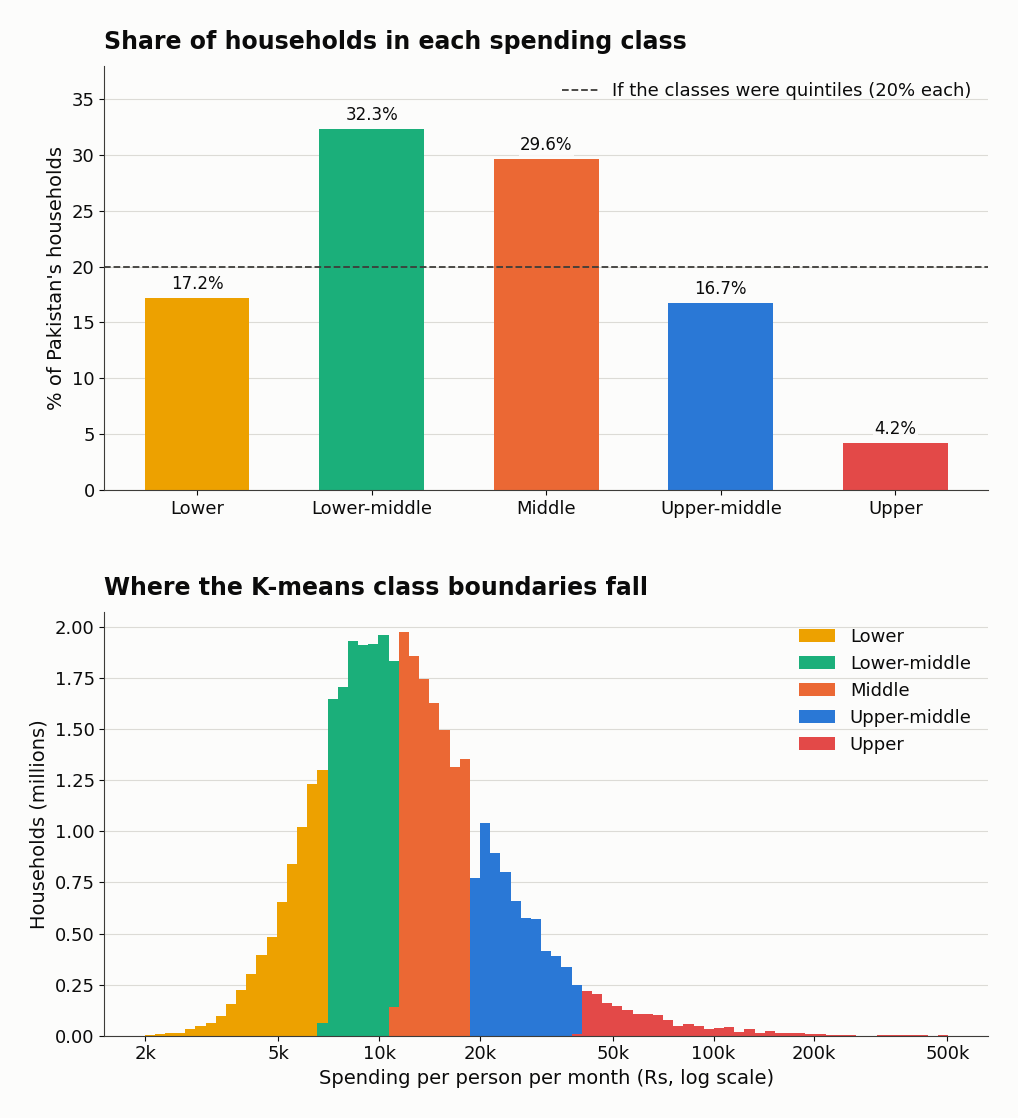

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 11))

ax = axes[0]
share = test_a["% of households"].to_numpy()
bars = ax.bar(test_a["class"], share, color=CLASS_COLORS, width=0.6)
ax.set_ylim(0, 38)
ax.axhline(20, color=INK_2, lw=1.3, ls="--", label="If the classes were quintiles (20% each)")
label_bars(ax, bars, "{:.1f}%")
style(ax, "% of Pakistan's households")
ax.set_title("Share of households in each spending class")
ax.legend(frameon=False, loc="upper right")

ax = axes[1]
bins = np.logspace(np.log10(hh.per_person.min()), np.log10(hh.per_person.max()), 80)
for k in range(1, 6):
    d = hh[hh.class_A == k]
    ax.hist(d.per_person, bins=bins, weights=d.weight / 1e6, color=CLASS_COLORS[k - 1], label=CLASS_NAMES[k])
ax.set_xscale("log")
ticks = [2000, 5000, 10000, 20000, 50000, 100000, 200000, 500000]
ax.set_xticks(ticks, [f"{t // 1000}k" for t in ticks]); ax.minorticks_off()
ax.set_xlabel("Spending per person per month (Rs, log scale)")
style(ax, "Households (millions)")
ax.set_title("Where the K-means class boundaries fall")
ax.legend(frameon=False, loc="upper right")

plt.tight_layout(h_pad=3)
plt.savefig(OUT + "test_a_classes.png")
plt.show()

## What if we forget the weight?

Same K-means, but every sampled household counts once, and the shares are counted over the sample. This is the mistake the weight protects against.


In [8]:
hh["class_A_unweighted"] = kmeans_classes(X_level, None)
compare = pd.DataFrame({
    "class": [CLASS_NAMES[k] for k in range(1, 6)],
    "% of households (weighted, correct)": test_a["% of households"].to_numpy(),
    "% of sample (no weight)": hh.class_A_unweighted.value_counts(normalize=True).sort_index().to_numpy() * 100,
})
# Province mix of the sample vs. all households in Pakistan
prov = hh.groupby("province").agg(sample=("hhcode", "size"), people=("weight", "sum"))
prov.index = prov.index.map({1: "KP", 2: "Punjab + ICT", 3: "Sindh", 4: "Balochistan"})
prov = (prov / prov.sum() * 100).rename(columns={"sample": "% of sample households", "people": "% of Pakistan's households (weighted)"})
display(compare)
display(prov)

,class,"% of households (weighted, correct)",% of sample (no weight)
0,Lower,17.2,16.6
1,Lower-middle,32.3,31.8
2,Middle,29.6,29.4
3,Upper-middle,16.7,17.7
4,Upper,4.2,4.5


,% of sample households,% of Pakistan's households (weighted)
province,,
KP,18.6,14.8
Punjab + ICT,44.8,55.7
Sindh,27.6,24.3
Balochistan,9.0,5.2


## Step 5: Test B, weighted K-means on the *pattern* of spending

Instead of one number, each household is described by **12 numbers**: spending per person on food, tobacco, clothing, housing, furnishings, health, transport, communication, recreation, education, restaurants, and personal care.

These are on a log scale (`log(1 + Rs)`, so a zero stays zero) and standardised with weighted means, so no category dominates just because it costs more.

**Theory:** if classes are real "ways of living", K-means should find them in this pattern.


In [9]:
pattern = np.log1p(hh[CATS].div(hh.hhsize, axis=0))
mu = np.average(pattern, axis=0, weights=hh.weight)
sd = np.sqrt(np.average((pattern - mu) ** 2, axis=0, weights=hh.weight))
Z = ((pattern - mu) / sd).to_numpy()

km_b = KMeans(n_clusters=5, n_init=20, random_state=42).fit(Z, sample_weight=hh.weight)
# Number clusters from poorest to richest by average spending per person
avg = pd.Series({c: wmean(hh.per_person[km_b.labels_ == c], hh.weight[km_b.labels_ == c]) for c in range(5)})
hh["class_B"] = pd.Series(km_b.labels_).map({c: r + 1 for r, c in enumerate(avg.sort_values().index)}).to_numpy()
test_b = summary("class_B")
display(test_b)

# How do Test B clusters line up with quintiles?  (row = cluster, % of its households in each quintile)
cross = pd.crosstab(hh.class_B, hh.quintile, values=hh.weight, aggfunc="sum", normalize="index") * 100
cross.index = [f"Cluster {k}" for k in cross.index]; cross.columns = [f"Q{c}" for c in cross.columns]
display(cross.round(0))

# What makes each cluster different? Share of its households with ZERO spending on a category
zero = pd.DataFrame({cat: hh.groupby("class_B").apply(
    lambda d: (d.weight * (d[cat] == 0)).sum() / d.weight.sum() * 100, include_groups=False)
    for cat in ["Tobacco", "Education", "Recreation", "Restaurants & hotels"]})
zero.index = [f"Cluster {k}" for k in zero.index]
display(zero.round(0).add_suffix(" = 0 (% of households)"))

,class,% of households,households (million),sample households,Rs/person/month from,to,average Rs/person/month
class_B,,,,,,,
1,Lower,19.4,7.8,6654,"1,991.0","91,985.0","7,263.0"
2,Lower-middle,27.3,11.0,8392,"3,727.0","42,047.0","8,948.0"
3,Middle,22.5,9.0,6594,"5,637.0","260,420.0","16,530.0"
4,Upper-middle,21.7,8.7,6111,"8,020.0","203,141.0","17,149.0"
5,Upper,9.1,3.6,2372,"16,618.0","501,810.0","46,995.0"


,Q1,Q2,Q3,Q4,Q5
Cluster 1,65.0,22.0,8.0,3.0,2.0
Cluster 2,26.0,45.0,24.0,4.0,0.0
Cluster 3,1.0,12.0,28.0,37.0,22.0
Cluster 4,0.0,3.0,26.0,46.0,26.0
Cluster 5,0.0,0.0,0.0,1.0,99.0


,Tobacco = 0 (% of households),Education = 0 (% of households),Recreation = 0 (% of households),Restaurants & hotels = 0 (% of households)
Cluster 1,57.0,82.0,60.0,28.0
Cluster 2,58.0,29.0,0.0,30.0
Cluster 3,55.0,97.0,70.0,18.0
Cluster 4,68.0,2.0,0.0,9.0
Cluster 5,67.0,43.0,14.0,4.0


## Step 6: KNN, can the class be recognised from the spending pattern?

Now that Test A has given every household a class label, KNN has something to learn.

- **Features:** the 12-category spending pattern (`Z` from Test B).
- **Label:** the Test A class.
- 75% of households train the model and 25% are held back to test it.
- Accuracy is **weighted**, so it measures how often the class is right for *households in Pakistan*.

High accuracy means the classes are not just arbitrary cuts of one number: households in the same class really do spend in similar ways.

In [10]:
X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(
    Z, hh.class_A, hh.weight, test_size=0.25, random_state=42, stratify=hh.class_A)

results = {}
for k in [5, 15, 25, 51]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_tr, y_tr)
    results[k] = accuracy_score(y_te, knn.predict(X_te), sample_weight=w_te) * 100
print("Weighted accuracy on held-out households:", {k: f"{v:.1f}%" for k, v in results.items()})

best_k = max(results, key=results.get)
knn = KNeighborsClassifier(n_neighbors=best_k).fit(X_tr, y_tr)
pred = knn.predict(X_te)
conf = pd.crosstab(pd.Series(y_te.to_numpy(), name="true class"), pd.Series(pred, name="predicted"),
                   values=w_te.to_numpy(), aggfunc="sum", normalize="index") * 100
conf.index = [CLASS_NAMES[k] for k in conf.index]; conf.columns = [CLASS_NAMES[k] for k in conf.columns]
print(f"\nk = {best_k}. Rows: true class; values: % of that class's households predicted as each class")
conf.round(0)

Weighted accuracy on held-out households: {5: '82.6%', 15: '82.9%', 25: '82.6%', 51: '81.2%'}



k = 15. Rows: true class; values: % of that class's households predicted as each class


,Lower,Lower-middle,Middle,Upper-middle,Upper
Lower,90.0,10.0,0.0,0.0,0.0
Lower-middle,7.0,90.0,2.0,0.0,0.0
Middle,0.0,18.0,80.0,1.0,0.0
Upper-middle,0.0,1.0,26.0,72.0,0.0
Upper,0.0,0.0,1.0,43.0,55.0


## Step 7: Adding income from Section 1B

`sec_1b_emp_income` has one row per person aged 10+, with what each person **earned**. The CSV copy, `CSV data/sec_1b_emp_income.csv`, holds the same numbers; we read the Stata file to stay consistent with the rest of the notebook.

| Column | Meaning | How we use it |
|---|---|---|
| `s1bq06` | Cash earned last month (main job) | × months worked (`s1bq07`) if there is no yearly figure |
| `s1bq08` | Cash earned last year (main job) | used first, when reported |
| `s1bq10` | Second job, last year | added |
| `s1bq11` | Other jobs, last year | added |
| `s1bq12` | Payment in kind that was sold | added |
| `s1bq13` | Pension and benefits, last year | added |

Household income = everyone's yearly total ÷ 12.

**Important:** Section 1B asks how much each person earned **in cash**: wages, the cash profit of their own shop, business or farm, and pensions. It does **not** include remittances or BISP (Section 8), rent and profit (Section 9), or income received **as goods** (food a family grows and eats, the rental value of a house it owns). Step 8 adds all of these.

**The key point: the class cut points are not salaries.** They are spending **per person** (cut points in Step 4). A household's earnings are shared by everyone living in it:

> One earner on Rs 40,000 supporting a family of 6 → Rs 40,000 ÷ 6 = **Rs 6,667 per person** → *lower* class (the lower class ends at Rs 6,999).
> To be *upper* class, a family of 6 must spend more than 6 × 40,282 = **Rs 241,700 a month**.


In [11]:
emp = read("sec_1b_emp_income.dta")
emp["hhcode"] = emp.hhcode.round().astype("int64")
pos = lambda col: emp[col].fillna(0).clip(lower=0)

months_worked = emp.s1bq07.fillna(12).clip(1, 12)
main_job_year = np.where(pos("s1bq08") > 0, pos("s1bq08"), pos("s1bq06") * months_worked)
emp["income_year"] = main_job_year + pos("s1bq10") + pos("s1bq11") + pos("s1bq12") + pos("s1bq13")
emp["is_earner"] = emp.income_year > 0
# One worker's monthly pay from the main job (for the "salary" comparison)
emp["main_job_month"] = np.where(pos("s1bq06") > 0, emp.s1bq06, np.where(pos("s1bq08") > 0, emp.s1bq08 / 12, np.nan))

income = emp.groupby("hhcode").agg(income_month=("income_year", lambda s: s.sum() / 12),
                                   earners=("is_earner", "sum")).reset_index()
hh = hh.drop(columns=["income_month", "earners"], errors="ignore").merge(income, on="hhcode", how="left")
hh[["income_month", "earners"]] = hh[["income_month", "earners"]].fillna(0)
hh["income_per_person"] = hh.income_month / hh.hhsize

def wmedian(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    o = np.argsort(x); cw = np.cumsum(w[o])
    return x[o][np.searchsorted(cw, cw[-1] / 2)]

profile = pd.DataFrame({
    CLASS_NAMES[k]: {
        "people per household": wmean(g.hhsize, g.weight),
        "earners per household": wmean(g.earners, g.weight),
        "household spending / month (median Rs)": wmedian(g.monthly_total, g.weight),
        "household job income / month (median Rs)": wmedian(g.income_month, g.weight),
        "spending per person (median Rs)": wmedian(g.per_person, g.weight),
        "job income per person (median Rs)": wmedian(g.income_per_person, g.weight),
    } for k, g in hh.groupby("class_A")})
profile.round(1)

,Lower,Lower-middle,Middle,Upper-middle,Upper
people per household,7.6,6.5,5.5,4.7,4.1
earners per household,1.8,1.6,1.5,1.3,1.2
household spending / month (median Rs),"38,317.6","54,420.1","73,303.9","108,366.1","229,895.8"
household job income / month (median Rs),"28,000.0","37,500.0","48,000.0","65,000.0","120,000.0"
spending per person (median Rs),"5,734.9","9,028.9","14,268.6","24,409.5","56,893.2"
job income per person (median Rs),"4,125.0","6,428.6","10,000.0","16,428.6","33,333.3"


In [12]:
# What does one WORKER earn from their main job, in each class?
workers = emp[emp.main_job_month > 0].merge(hh[["hhcode", "class_A", "weight"]], on="hhcode")
pay = pd.Series({CLASS_NAMES[k]: wmedian(g.main_job_month, g.weight) for k, g in workers.groupby("class_A")},
                name="median monthly pay of one worker (Rs)")
display(pay.to_frame())
share_40k = (workers.weight * (workers.main_job_month >= 40000)).sum() / workers.weight.sum() * 100
print(f"All workers: median pay Rs {wmedian(workers.main_job_month, workers.weight):,.0f}; "
      f"{share_40k:.0f}% earn Rs 40,000 or more a month")

both = hh[hh.income_per_person > 0]
r = np.corrcoef(np.log(both.per_person), np.log(both.income_per_person))[0, 1]
print(f"Correlation between spending per person and job income per person (logs): {r:.2f}")

,median monthly pay of one worker (Rs)
Lower,"16,000.0"
Lower-middle,"22,916.7"
Middle,"30,000.0"
Upper-middle,"48,000.0"
Upper,"98,000.0"


All workers: median pay Rs 25,000; 28% earn Rs 40,000 or more a month
Correlation between spending per person and job income per person (logs): 0.71


## Step 8: Full income (cash, transfers, property and income in kind), and classes based on income

**Business and farm cash income are already inside Section 1B.** For employers, shopkeepers and farmers, the "main job" amount *is* their net cash income from the business or farm. The check below confirms it for businesses, so adding Section 11 again would **count the same money twice**.

What Section 1B does **not** include, and we add now:

| Source | File and codes |
|---|---|
| Remittances from within Pakistan | `sec_8a` code 802 |
| Remittances from abroad | `sec_8a` codes 805-808 (by bank, hundi, mobile, other). Code 804 is only yes/no. |
| BISP / Ehsaas and other government aid | `sec_8a` codes 820, 821 |
| Zakat and help from public or private sources | `sec_8a` codes 812, 813. Code 811 is only yes/no. |
| Boarders' rent, gifts received and sold | `sec_8a` codes 817, 819 |
| Rent received from land, buildings, business property, farm equipment | `sec_9a` Q4, `sec_11` codes 288-289, `sec_10a` code 197 |
| Profit on savings, dividends, interest on loans given | `sec_9b` codes 953, 960, 970 |
| **Income in kind**: food and goods the household produced and used itself, the rental value of a house it owns and lives in (code 42101), wages paid in goods, gifts received as goods | `sec_6a` columns `v3` (own production), `v2` (wages in kind), `v4` (gifts) |

Sections 8 and 9 ask about the last year, so those amounts are ÷ 12. Income in kind uses the same monthly conversion as spending.

**Why income in kind must be counted.** Spending includes the market value of everything a household *used*, including the wheat it grew and the house it owns. That value was never paid in cash, so it is not in Section 1B. If we leave it out of income but keep it in spending, spending looks larger than income, which is impossible. PBS counts it on both sides (report, sections 2.3.7 and 2.4.2), and so do we.

**Not income** (left out): selling assets or gold, loans taken, savings withdrawn, committees, inheritance and dowry, and one-off insurance claims.

In [13]:
# Check: a self-employed person's Section 11 profit vs. what they reported in Section 1B
biz = read("sec_11ab_nonagri.dta")
biz["hhcode"] = biz.hhcode.round().astype("int64")
biz["s11c"] = biz.s11c.fillna(0)
key = ["hhcode", "idc", "sheetno"]
amount = lambda codes: biz[biz.code.isin(codes)].groupby(key).s11c.sum()
revenue = amount(range(251, 260)).add(amount(range(266, 279)), fill_value=0)
costs = amount(range(201, 212)).add(amount(range(221, 230)), fill_value=0).add(amount(range(241, 246)), fill_value=0)
profit = revenue.sub(costs, fill_value=0).rename("sheet_profit").reset_index().groupby(["hhcode", "idc"]).sheet_profit.sum()

self_emp = emp[emp.s1bq02.isin([1, 2, 3])].set_index(["hhcode", "idc"])
both = self_emp.join(profit, how="inner")
both = both[both.income_year > 0]
ratio = both.sheet_profit / (both.income_year - pos("s1bq13").reindex(both.index, fill_value=0))
print(f"{len(both):,} self-employed people have a business sheet.")
print(f"Sheet profit ÷ Section 1B earnings: median {ratio.median():.2f}; "
      f"within ±25% for {((ratio - 1).abs() <= 0.25).mean() * 100:.0f}% of them")

6,425 self-employed people have a business sheet.
Sheet profit ÷ Section 1B earnings: median 1.02; within ±25% for 71% of them


In [14]:
def yearly_by_hh(df, codes, col):
    d = df[df.code.isin(codes)].copy()
    d["hhcode"] = d.hhcode.round().astype("int64")
    return d.groupby("hhcode")[col].sum()

transfers_8a = read("sec_8a.dta")
prop_9a, fin_9b, agri_10a = read("sec_9a.dta"), read("sec_9b.dta"), read("sec_10a_agrisheet.dta")

SOURCES = {
    "remittances (Pakistan)": yearly_by_hh(transfers_8a, [802], "c02"),
    "remittances (abroad)": yearly_by_hh(transfers_8a, [805, 806, 807, 808], "c02"),
    "BISP & govt aid": yearly_by_hh(transfers_8a, [820, 821], "c02"),
    "zakat & help": yearly_by_hh(transfers_8a, [812, 813], "c02"),
    "boarders & gifts sold": yearly_by_hh(transfers_8a, [817, 819], "c02"),
    "rent received": yearly_by_hh(prop_9a, [901, 902, 903, 904], "s9aq04")
        .add(yearly_by_hh(biz, [288, 289], "s11a"), fill_value=0)
        .add(yearly_by_hh(agri_10a, [197], "s10c1"), fill_value=0),
    "profit & dividends": yearly_by_hh(fin_9b, [953, 960, 970], "c02"),
}
extra = (pd.DataFrame(SOURCES).reindex(hh.hhcode).fillna(0).clip(lower=0) / 12).reset_index(drop=True)
TRANSFER_COLS = list(SOURCES)[:5]
hh = hh.drop(columns=list(SOURCES), errors="ignore")
hh = pd.concat([hh.reset_index(drop=True), extra], axis=1)
hh["transfers"] = hh[TRANSFER_COLS].sum(axis=1)
hh["property_income"] = hh[["rent received", "profit & dividends"]].sum(axis=1)
# Income in kind: the part of spending that was never paid in cash (columns v2, v3, v4 of Section 6A)
kind = items[["hhcode", "part", "v2", "v3", "v4"]].copy()
for v in ["v2", "v3", "v4"]:
    kind[v] = kind[v].fillna(0).clip(lower=0) * kind.part.map(PER_MONTH)
kind["hhcode"] = kind.hhcode.astype("int64")
in_kind = kind.groupby("hhcode")[["v2", "v3", "v4"]].sum().sum(axis=1)
hh["in_kind"] = hh.hhcode.map(in_kind).fillna(0).to_numpy()

hh["full_income"] = hh.income_month + hh.transfers + hh.property_income + hh.in_kind
hh["full_income_pp"] = hh.full_income / hh.hhsize

by_class = pd.DataFrame({
    CLASS_NAMES[k]: {
        "jobs, business & farm (Rs)": wmean(g.income_month, g.weight),
        "transfers (Rs)": wmean(g.transfers, g.weight),
        "property income (Rs)": wmean(g.property_income, g.weight),
        "income in kind (Rs)": wmean(g.in_kind, g.weight),
        "FULL income (Rs)": wmean(g.full_income, g.weight),
        "spending (Rs)": wmean(g.monthly_total, g.weight),
        "% of households getting remittances from abroad": (g.weight * (g["remittances (abroad)"] > 0)).sum() / g.weight.sum() * 100,
        "% of households getting BISP / govt aid": (g.weight * (g["BISP & govt aid"] > 0)).sum() / g.weight.sum() * 100,
    } for k, g in hh.groupby("class_A")})
print("Check against the official PBS report (Tables 3.5.A and 3.6.A), average per household per month:")
print(f"  income:   ours Rs {wmean(hh.full_income, hh.weight):,.0f}   PBS Rs 82,179")
print(f"  spending: ours Rs {wmean(hh.monthly_total, hh.weight):,.0f}   PBS Rs 79,150")
print("\nAverage per household per month, by spending class (weighted):")
by_class.round(0)

Check against the official PBS report (Tables 3.5.A and 3.6.A), average per household per month:
  income:   ours Rs 84,057   PBS Rs 82,179
  spending: ours Rs 81,351   PBS Rs 79,150

Average per household per month, by spending class (weighted):


,Lower,Lower-middle,Middle,Upper-middle,Upper
"jobs, business & farm (Rs)","31,525.0","42,155.0","55,663.0","82,244.0","167,072.0"
transfers (Rs),"4,136.0","6,420.0","11,255.0","19,789.0","34,236.0"
property income (Rs),320.0,767.0,"1,788.0","3,408.0","10,529.0"
income in kind (Rs),"7,899.0","10,765.0","13,916.0","19,924.0","66,638.0"
FULL income (Rs),"43,880.0","60,108.0","82,622.0","125,365.0","278,475.0"
spending (Rs),"41,608.0","58,503.0","80,188.0","118,966.0","278,311.0"
% of households getting remittances from abroad,3.0,6.0,12.0,17.0,18.0
% of households getting BISP / govt aid,41.0,28.0,14.0,6.0,3.0


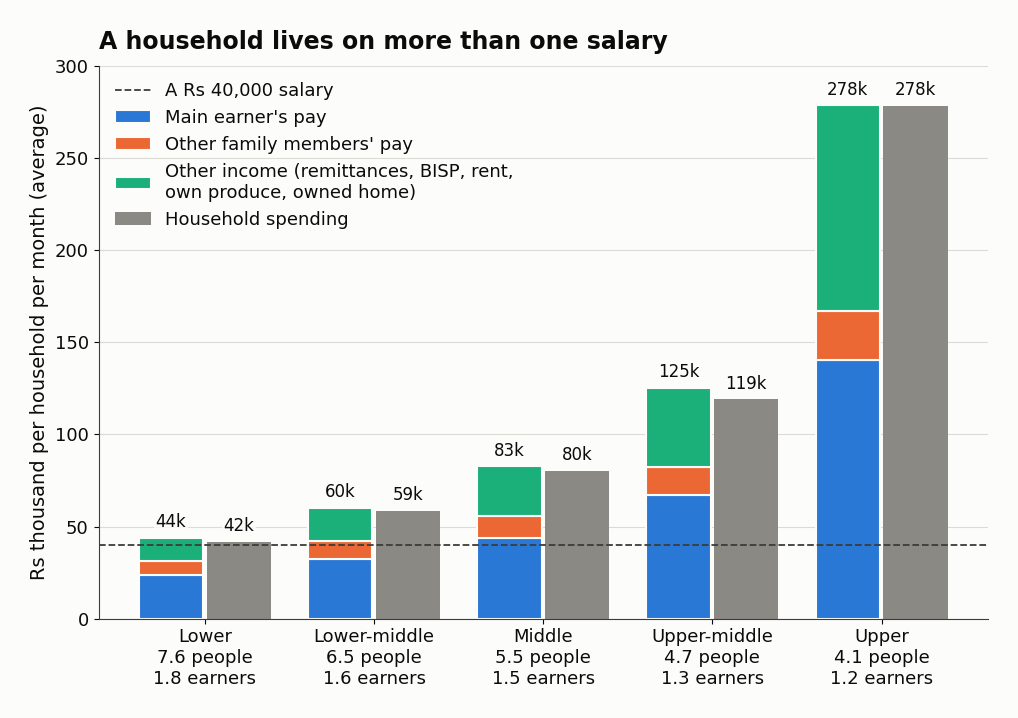

Main earner's pay as % of household income: {'Lower': '54%', 'Lower-middle': '54%', 'Middle': '53%', 'Upper-middle': '54%', 'Upper': '50%'}


In [15]:
# Chart: why a household spends more than one worker earns
earn = emp.groupby("hhcode").income_year.max() / 12            # the household's highest earner
hh["main_earner"] = hh.hhcode.map(earn).fillna(0).to_numpy()
hh["other_earners"] = hh.income_month - hh.main_earner
hh["other_income"] = hh.transfers + hh.property_income + hh.in_kind
avg = lambda col: np.array([wmean(g[col], g.weight) for _, g in hh.groupby("class_A")]) / 1000

fig, ax = plt.subplots(figsize=(10, 7))
bw = 0.38
bottom = np.zeros(5)
for col, label, colour in [("main_earner", "Main earner's pay", SERIES[0]),
                           ("other_earners", "Other family members' pay", SERIES[1]),
                           ("other_income", "Other income (remittances, BISP, rent,\nown produce, owned home)", SERIES[2])]:
    v = avg(col)
    stack = ax.bar(XPOS - bw / 2 - 0.01, v, bw, bottom=bottom, color=colour, label=label, edgecolor=SURFACE, linewidth=1.5)
    bottom += v
spend_bars = ax.bar(XPOS + bw / 2 + 0.01, avg("monthly_total"), bw, color="#8a8983", label="Household spending")
ax.axhline(40, color=INK_2, lw=1.3, ls="--", label="A Rs 40,000 salary", zorder=1)
ax.set_ylim(0, 300)
label_bars(ax, stack, "{:.0f}k"); label_bars(ax, spend_bars, "{:.0f}k")
people, earners = avg("hhsize") * 1000, avg("earners") * 1000
ax.set_xticks(XPOS, [f"{n}\n{p:.1f} people\n{e:.1f} earners" for n, p, e in zip(NAMES, people, earners)])
style(ax, "Rs thousand per household per month (average)")
ax.set_title("A household lives on more than one salary")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(OUT + "household_vs_salary.png"); plt.show()

print("Main earner's pay as % of household income:",
      {CLASS_NAMES[k]: f"{wmean(g.main_earner, g.weight) / wmean(g.full_income, g.weight) * 100:.0f}%" for k, g in hh.groupby("class_A")})

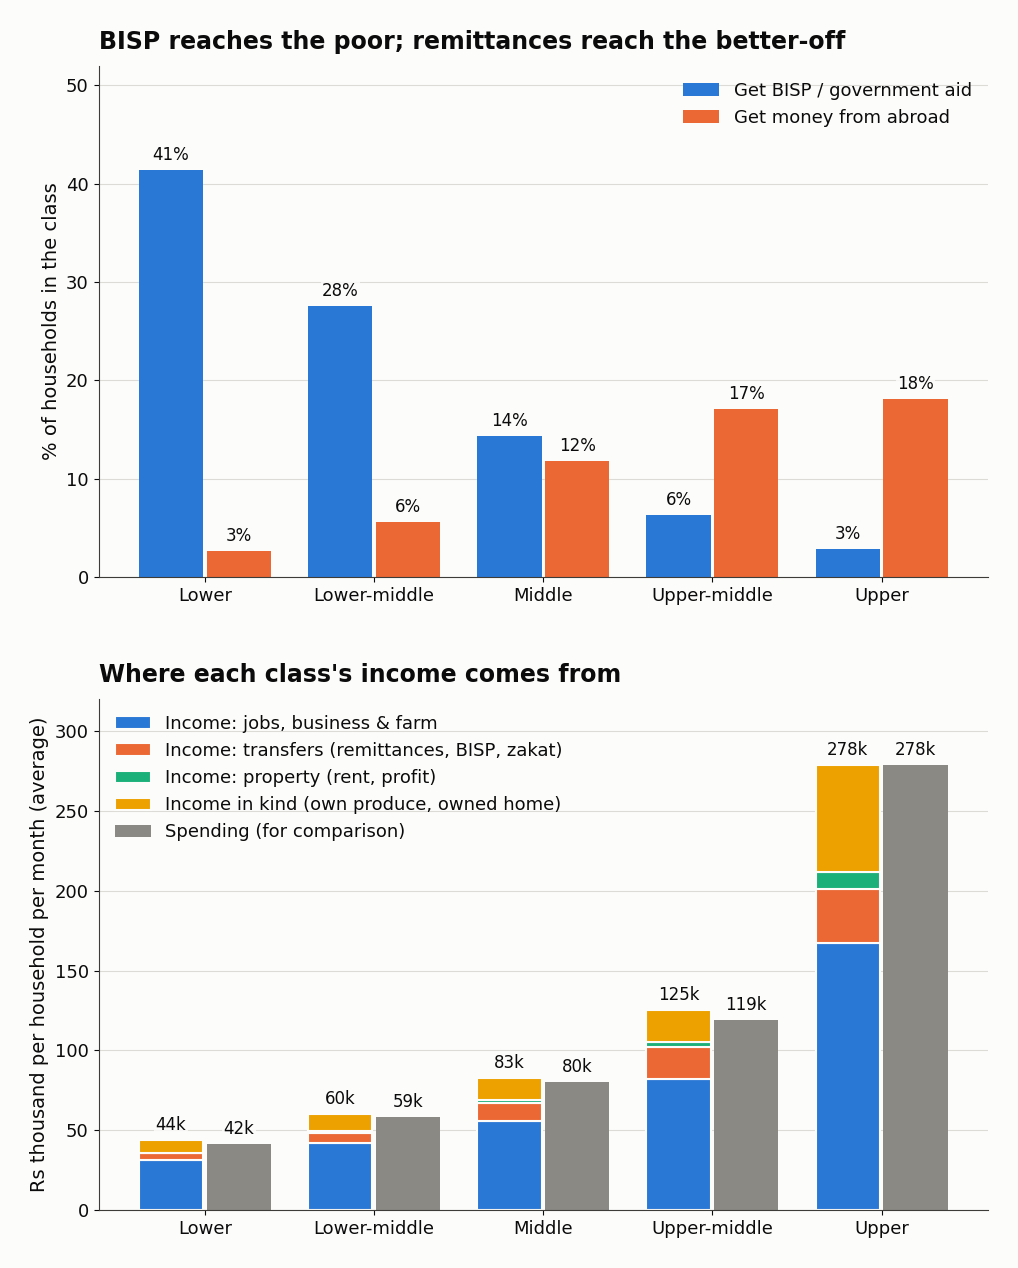

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(10, 12.5))

ax = axes[0]
bw = 0.38
b1 = ax.bar(XPOS - bw / 2 - 0.01, by_class.loc["% of households getting BISP / govt aid"], bw, color=SERIES[0], label="Get BISP / government aid")
b2 = ax.bar(XPOS + bw / 2 + 0.01, by_class.loc["% of households getting remittances from abroad"], bw, color=SERIES[1], label="Get money from abroad")
ax.set_ylim(0, 52)
label_bars(ax, b1, "{:.0f}%"); label_bars(ax, b2, "{:.0f}%")
ax.set_xticks(XPOS, NAMES)
style(ax, "% of households in the class")
ax.set_title("BISP reaches the poor; remittances reach the better-off")
ax.legend(frameon=False, loc="upper right")

ax = axes[1]
parts = [("jobs, business & farm (Rs)", "Income: jobs, business & farm"),
         ("transfers (Rs)", "Income: transfers (remittances, BISP, zakat)"),
         ("property income (Rs)", "Income: property (rent, profit)"),
         ("income in kind (Rs)", "Income in kind (own produce, owned home)")]
bottom = np.zeros(5)
for (row, label), colour in zip(parts, SERIES + ["#eda100"]):
    v = by_class.loc[row].to_numpy() / 1000
    stack = ax.bar(XPOS - bw / 2 - 0.01, v, bw, bottom=bottom, color=colour, label=label, edgecolor=SURFACE, linewidth=1.5)
    bottom += v
spend_bars = ax.bar(XPOS + bw / 2 + 0.01, by_class.loc["spending (Rs)"] / 1000, bw, color="#8a8983", label="Spending (for comparison)")
ax.set_ylim(0, 320)
label_bars(ax, stack, "{:.0f}k")          # top of the stack = total income
label_bars(ax, spend_bars, "{:.0f}k")
ax.set_xticks(XPOS, NAMES)
style(ax, "Rs thousand per household per month (average)")
ax.set_title("Where each class's income comes from")
ax.legend(frameon=False, loc="upper left")

plt.tight_layout(h_pad=3); plt.savefig(OUT + "income_sources.png"); plt.show()

### Test C: K-means on **full income** per person

Same method as Test A (households weighted by the household weight), using full income per person instead of spending.

A few households report almost no income: under-reporting is common in income surveys. On a log scale those values sit far away from everyone else and would capture whole clusters. So we **winsorize** before clustering: anyone below the 1st percentile (weighted) is raised to the 1st-percentile value.

In [17]:
srt = hh.sort_values("full_income_pp")
p1 = srt.full_income_pp[(srt.weight.cumsum() / srt.weight.sum()) >= 0.01].iloc[0]
X_income = np.log(hh[["full_income_pp"]].clip(lower=p1).to_numpy())
print(f"1st percentile of full income per person: Rs {p1:,.0f}")

hh["class_C"], centres_C = kmeans_fit(X_income, hh.weight)
g = hh.groupby("class_C")
test_c = pd.DataFrame({
    "class": [CLASS_NAMES[k] for k in g.groups],
    "% of households (by INCOME)": g.weight.sum() / hh.weight.sum() * 100,
    "income per person from (Rs)": g.full_income_pp.min().round(0),
    "to": g.full_income_pp.max().round(0),
})
test_c["% of households (by SPENDING, Test A)"] = test_a["% of households"].to_numpy()
display(test_c)
print("Test C cut points (full income per person per month, after raising the bottom 1% to the 1st percentile):")
display(cut_table(centres_C, hh.full_income_pp.clip(lower=p1).to_numpy(), hh.class_C.to_numpy()))

agree = pd.crosstab(hh.class_A, hh.class_C, values=hh.weight, aggfunc="sum", normalize="index") * 100
agree.index = [f"spending: {CLASS_NAMES[k]}" for k in agree.index]
agree.columns = [f"income: {CLASS_NAMES[k]}" for k in agree.columns]
display(agree.round(0))
same = (hh.weight * (hh.class_A == hh.class_C)).sum() / hh.weight.sum() * 100
near = (hh.weight * ((hh.class_A - hh.class_C).abs() <= 1)).sum() / hh.weight.sum() * 100
print(f"Same class by income and by spending: {same:.0f}% of households; same or next-door class: {near:.0f}%")

1st percentile of full income per person: Rs 3,238


,class,% of households (by INCOME),income per person from (Rs),to,"% of households (by SPENDING, Test A)"
class_C,,,,,
1,Lower,19.6,0.0,"6,938.0",17.2
2,Lower-middle,33.7,"6,940.0","11,781.0",32.3
3,Middle,28.1,"11,783.0","20,690.0",29.6
4,Upper-middle,14.4,"20,694.0","45,342.0",16.7
5,Upper,4.2,"45,442.0","730,000.0",4.2


Test C cut points (full income per person per month, after raising the bottom 1% to the 1st percentile):
Households where 'apply the cut points' = K-means class: 100.00%


,class,centre (Rs/person/month),lower cut (Rs),upper cut (Rs)
0,Lower,"5,287.0",NaN,"6,939.0"
1,Lower-middle,"9,108.0","6,939.0","11,783.0"
2,Middle,"15,243.0","11,783.0","20,692.0"
3,Upper-middle,"28,089.0","20,692.0","45,384.0"
4,Upper,"73,328.0","45,384.0",NaN


,income: Lower,income: Lower-middle,income: Middle,income: Upper-middle,income: Upper
spending: Lower,80.0,18.0,1.0,0.0,0.0
spending: Lower-middle,16.0,70.0,13.0,1.0,0.0
spending: Middle,2.0,25.0,63.0,10.0,0.0
spending: Upper-middle,1.0,2.0,29.0,61.0,7.0
spending: Upper,1.0,1.0,3.0,26.0,69.0


Same class by income and by spending: 68% of households; same or next-door class: 98%


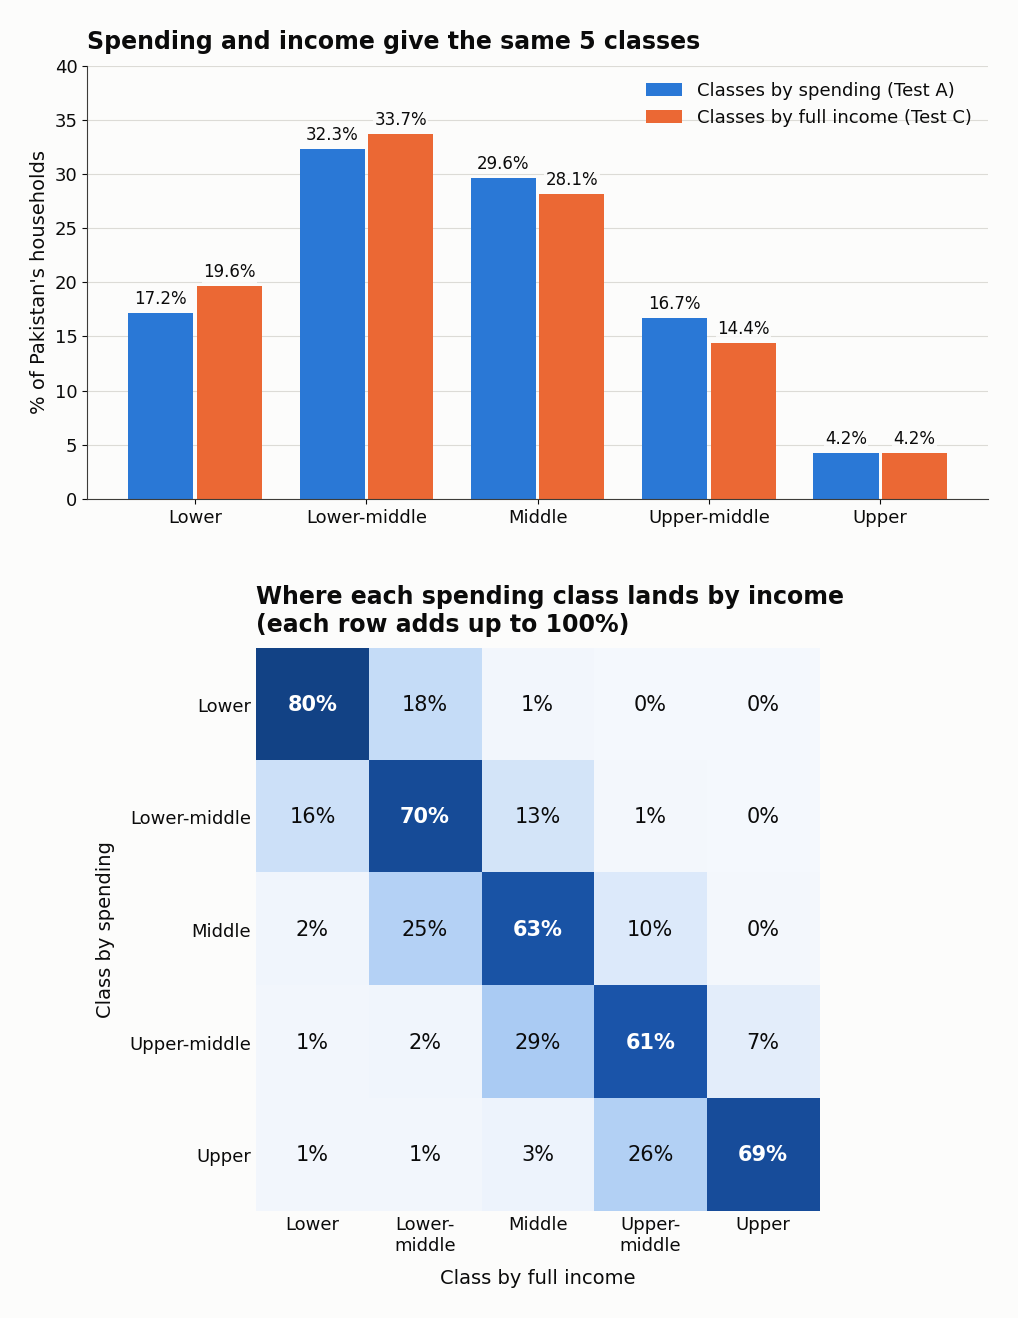

In [18]:
from matplotlib.colors import LinearSegmentedColormap
fig, axes = plt.subplots(2, 1, figsize=(10, 13), gridspec_kw={"height_ratios": [1, 1.3]})

ax = axes[0]
bw = 0.38
b1 = ax.bar(XPOS - bw / 2 - 0.01, test_c["% of households (by SPENDING, Test A)"], bw, color=SERIES[0], label="Classes by spending (Test A)")
b2 = ax.bar(XPOS + bw / 2 + 0.01, test_c["% of households (by INCOME)"], bw, color=SERIES[1], label="Classes by full income (Test C)")
ax.set_ylim(0, 40)
label_bars(ax, b1, "{:.1f}%"); label_bars(ax, b2, "{:.1f}%")
ax.set_xticks(XPOS, NAMES)
style(ax, "% of Pakistan's households")
ax.set_title("Spending and income give the same 5 classes")
ax.legend(frameon=False, loc="upper right")

ax = axes[1]
blues = LinearSegmentedColormap.from_list("blues", [(0, "#f4f8fd"), (0.35, "#9cc3f2"), (0.55, "#1d5bb5"), (1, "#0b2f61")])
m = agree.to_numpy()
ax.imshow(m, cmap=blues, vmin=0, vmax=100)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{m[i, j]:.0f}%", ha="center", va="center", fontsize=15,
                fontweight="bold" if i == j else "normal", color=text_colour_on(blues(m[i, j] / 100)))
wrapped = [n.replace("-", "-\n") for n in NAMES]
ax.set_xticks(range(5), wrapped)
ax.set_yticks(range(5), NAMES)
ax.tick_params(length=0)
ax.set_xlabel("Class by full income", labelpad=10)
ax.set_ylabel("Class by spending", labelpad=10)
ax.set_title("Where each spending class lands by income\n(each row adds up to 100%)")
for side in ax.spines.values(): side.set_visible(False)

plt.tight_layout(h_pad=3); plt.savefig(OUT + "spending_vs_income_classes.png"); plt.show()

In [19]:
keep = ["hhcode", "prcode", "province", "region", "hhsize", "weight", "people_w",
        "monthly_total", "per_person", "income_month", "earners", "income_per_person",
        "transfers", "property_income", "in_kind", "full_income", "full_income_pp",
        "quintile", "class_A", "class_B", "class_C"] + CATS
saved = hh[keep].copy()
saved.insert(saved.columns.get_loc("class_A") + 1, "class_A_name", saved.class_A.map(CLASS_NAMES))
saved.insert(saved.columns.get_loc("class_C") + 1, "class_C_name", saved.class_C.map(CLASS_NAMES))
saved["province"] = saved.province.map({1: "kp", 2: "punjab", 3: "sindh", 4: "balochistan"})
saved["region"] = saved.region.map({1: "rural", 2: "urban"})
saved.round(1).to_csv(OUT + "household_classes.csv", index=False, encoding="utf-8-sig")
test_a.to_csv(OUT + "test_a_class_summary.csv", encoding="utf-8-sig")
print("Saved:", sorted(os.listdir(OUT)))

Saved: ['household_classes.csv', 'household_vs_salary.png', 'income_sources.png', 'spending_vs_income_classes.png', 'test_a_class_summary.csv', 'test_a_classes.png']


## Conclusions

**Unit of analysis: the household.** Every share below is a share of Pakistan's **40.1 million households** (sum of the household weights). The population they represent is 239.8 million people (average household size 5.98).

### 1. Yes, weighted K-means divides households into 5 spending classes

Households are ranked by monthly spending **per person**. Cut points come from Step 4 (exact definition in `HOW_CLASSES_ARE_DEFINED.md`).

| Class | Spending per person per month | % of households | Households |
|---|---|---:|---:|
| Lower | below Rs 6,999 | 17.2% | 6.9 million |
| Lower-middle | Rs 6,999 – 11,399 | 32.3% | 13.0 million |
| Middle | Rs 11,399 – 19,120 | 29.6% | 11.9 million |
| Upper-middle | Rs 19,120 – 40,282 | 16.7% | 6.7 million |
| Upper | above Rs 40,282 | **4.2%** | **1.7 million** |

- Quintiles force 20% into every group. K-means shows that **62% of households sit in the lower-middle and middle classes**, and only **4% form a clearly separate upper class**. An upper-class household spends on average Rs 71,900 per person per month, 4.6 times the average household's Rs 15,550.
- The result is **stable**: with every start run to full convergence, different random seeds give the same classes (adjusted Rand index 0.998-1.000).

### 2. Clustering the *pattern* of spending finds household types, not classes

Test B clustered on 12 spending categories. Only its poorest and richest clusters line up with quintiles (65% of cluster 1 is in Q1; 99% of cluster 5 is in Q5). The middle clusters are split by **what** a household buys, not **how much**:

- in cluster 3, 97% of households spend nothing on education; in cluster 4, 98% do spend on education;
- in clusters 2 and 4, every household spends something on recreation; in cluster 3, 70% spend nothing on it.

So these clusters separate families with students from families without, rather than rich from poor. For "class", use spending per person (Test A).

### 3. KNN recognises the classes from spending patterns 83% of the time

Given only the 12-category spending pattern, KNN (k = 15) predicts the Test A class correctly for **82.9% of households** (weighted, on households it never saw). Almost every mistake (all but about 1%) is to a **neighbouring** class. The upper class is hardest (55% correct; 43% are predicted as upper-middle), because it is small and the line between "rich" and "very rich" is blurry. This means the classes are not arbitrary cuts: households in the same class really do spend alike.

### 4. The weight: needed for correctness, though here it shifts national shares by only about 1 point

- The sample is not a copy of Pakistan. Sindh and Balochistan are **36.6% of the sample but 29.5% of households**, and Punjab with Islamabad is 44.8% of the sample vs 55.7% of households. Only the weighted results describe Pakistan.
- For these national class shares the difference was small: no class moved by more than about 1 percentage point. Over-sampling in poorer and in richer areas partly cancels out. Do **not** assume this always happens: for provinces, rural/urban splits or other indicators, the gap can be several points.
- The weight is also what turns shares into **numbers of households**, such as "1.7 million upper-class households".

### 5. Income (Section 1B): what a household in each class looks like

| Class | People per household | Earners | Household spending / month | Household cash income from work / month | One worker's pay / month |
|---|---:|---:|---:|---:|---:|
| Lower | 7.6 | 1.8 | Rs 38,300 | Rs 28,000 | Rs 16,000 |
| Lower-middle | 6.5 | 1.6 | Rs 54,400 | Rs 37,500 | Rs 22,900 |
| Middle | 5.5 | 1.5 | Rs 73,300 | Rs 48,000 | Rs 30,000 |
| Upper-middle | 4.7 | 1.3 | Rs 108,400 | Rs 65,000 | Rs 48,000 |
| Upper | 4.1 | 1.2 | Rs 229,900 | Rs 120,000 | Rs 98,000 |

*(medians, weighted by household)*

- **The cut points are spending per person, not salaries.** A typical upper-class household spends about **Rs 230,000 a month**, and its main worker earns about **Rs 98,000**.
- **A Rs 40,000 salary does not go far.** One earner on Rs 40,000 supporting 6 people gives about Rs 6,667 per person, which is in the lower class. The median worker in Pakistan earns about **Rs 25,000**, and only about 28% earn Rs 40,000 or more.
- **Family size matters as much as pay.** Poorer households have almost **twice as many people** (7.6 vs 4.1) and only slightly more earners. The same salary stretches across more mouths.
- **Income and spending agree** (correlation 0.71). That's good: the spending classes are confirmed by a separate source.
- Section 1B counts **cash only**, so it is lower than spending in every class. The missing part is added in Step 8 (next point).

### 6. Full income: cash, transfers, property and income in kind

- **Business and farm cash income were already counted.** Section 1B's "main job" earnings are the net cash income of shopkeepers, employers and farmers. For self-employed people, the profit worked out from their Section 11 business sheet is almost the same number (median ratio 1.02). Adding Section 11 again would double-count it.
- **Income in kind must be added, or spending looks bigger than income.** Section 1B only asks about cash. But spending also includes things that were never paid for in cash: food a family grew and ate, the rental value of a house it owns, wages paid in goods, and gifts received as goods. These are worth **Rs 15,100 a month** for the average household (Rs 6,400 of it is the value of living in your own house). PBS counts them as income too.
- **With everything added, income is at least as high as spending in every class**, and our totals match the official PBS report:

| Average per household per month | Ours | PBS report 2024-25 |
|---|---:|---:|
| Income | Rs 84,057 | Rs 82,179 |
| Spending | Rs 81,351 | Rs 79,150 |

- **A household lives on more than one salary.** On average the main earner brings in only about **half (50-54%)** of the household's income. The rest comes from other family members who work, remittances, BISP, rent and income in kind. That is why a household's spending is much larger than one worker's pay.
- **Who gets what:**
  - **BISP / government aid** reaches 41% of lower-class households but only 3% of upper-class ones. It is well targeted at the poor.
  - **Remittances from abroad** go the other way: 3% of lower-class households receive them vs 18% of upper-class ones. Having a family member abroad is part of what puts a family higher up.
- **Classes by income look almost exactly like classes by spending:**

| Class | % of households by income (Test C) | % of households by spending (Test A) |
|---|---:|---:|
| Lower | 19.6% | 17.2% |
| Lower-middle | 33.7% | 32.3% |
| Middle | 28.1% | 29.6% |
| Upper-middle | 14.4% | 16.7% |
| Upper | 4.2% | 4.2% |

  68% of households land in the **same** class either way, and **98%** land in the same or a neighbouring class. Two independent measures give the same picture of society, which makes the 5-class result much more convincing.

### Limitations, before anyone quotes these numbers

- **One peak, not five groups.** Spending per person has a single hump (see the chart), so there are no "natural gaps" between classes. K-means picks the cut points that make each class as tight as possible. The classes are a sensible split, not something hidden in the data.
- **Spending is not wealth or income.** A household that bought a car or gold this year looks richer for one year.
- **No price adjustment.** Rs 10,000 buys more in a village than in Karachi or Lahore, and children are counted the same as adults. PBS's official method may adjust for these; see Appendix A of the report.
- **Part D recorded totals** disagree with their items for about 18% of households. We used the items.
